In [17]:
import os

os.environ.setdefault(
    "CUBLAS_WORKSPACE_CONFIG",
    ":4096:8"
)

from pathlib import Path
from datetime import datetime

import sys
import json
import time
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

In [18]:
PROJECT_DIR = Path(
    r"C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca"
)

DATASET_DIR = (
    PROJECT_DIR / "dataset" / "raw"
    / "cassava_dataset"
)

CONFIGS_DIR = PROJECT_DIR / "configs"
REPORTS_DIR = PROJECT_DIR / "reports"
MODELS_DIR = PROJECT_DIR / "models"
EXPERIMENTS_DIR = PROJECT_DIR / "experiments"

RUN_ID = "federated_cached_v1"
FINAL_RUN_ID = "final_cached_v1"

FED_MODELS_DIR = (
    MODELS_DIR / "federated" / RUN_ID
)

FED_REPORTS_DIR = (
    REPORTS_DIR / "federated" / RUN_ID
)

FED_EXPERIMENTS_DIR = (
    EXPERIMENTS_DIR / "federated" / RUN_ID
)

FINAL_REPORTS_DIR = (
    REPORTS_DIR / "final" / FINAL_RUN_ID
)

FINAL_EXPERIMENTS_DIR = (
    EXPERIMENTS_DIR / "final" / FINAL_RUN_ID
)

for directory in [
    FED_MODELS_DIR,
    FED_REPORTS_DIR,
    FED_EXPERIMENTS_DIR
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )

if str(PROJECT_DIR) not in sys.path:

    sys.path.insert(
        0,
        str(PROJECT_DIR)
    )

In [19]:
from src.utils import (
    set_seed,
    get_device
)

from src.experiments import save_json

from src.feature_cache import (
    FEATURE_DIMS,
    CLASSIFIER_ATTRIBUTES,
    calculate_sha256,
    dataframe_fingerprint,
    create_classifier,
    release_memory
)

from src.federated_training import (
    federated_average,
    clone_state_dict,
    run_federated_experiment
)

from src.final_training import load_final_model

from src.preprocessing import build_transforms

from src.dataset import CassavaDataset

In [20]:
def load_json(filepath):

    with open(
        filepath,
        "r",
        encoding="utf-8"
    ) as file:

        return json.load(file)


dataset_config = load_json(
    CONFIGS_DIR / "dataset_config.json"
)

final_config = load_json(
    CONFIGS_DIR / "final_training_config.json"
)

federated_config = load_json(
    CONFIGS_DIR / "federated_config.json"
)

fed_config = load_json(
    CONFIGS_DIR / "federated_training_config.json"
)

centralized_registry = load_json(
    CONFIGS_DIR / "centralized_model_registry.json"
)

SEED = fed_config["seed"]

CLASS_MAPPING = dataset_config["class_mapping"]

NUM_CLASSES = len(CLASS_MAPPING)

ARCHITECTURES = fed_config["architectures"]

CACHE_DIR = (
    PROJECT_DIR
    / fed_config["feature_cache_dir"]
)

DEVICE = get_device()

set_seed(SEED)

assert DEVICE.type == "cuda"

assert len(ARCHITECTURES) == 5

assert NUM_CLASSES == 5

assert fed_config["num_clients"] == 2

assert fed_config["num_servers"] == 1

assert fed_config["algorithm"] == "FedAvg"

assert fed_config["hyperparameters"] == (
    final_config["hyperparameters"]
)

print("GPU:", torch.cuda.get_device_name(0))
print("Device:", DEVICE)
print("Architectures:", ARCHITECTURES)

GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU
Device: cuda
Architectures: ['mobilenet_v3_large', 'efficientnet_b0', 'resnet50', 'vit_b_16', 'swin_t']


In [21]:
final_summary = load_json(
    FINAL_EXPERIMENTS_DIR
    / "final_training_summary.json"
)

assert final_summary["status"] == "completed"

assert final_summary["centralized_models_saved"] == 5

assert final_summary["models_verified"] == 5

assert not final_summary["test_used"]

assert len(
    centralized_registry["models"]
) == 5

print("Fase 2 verificada correctamente.")

Fase 2 verificada correctamente.


In [22]:
fed_config.update({

    "rounds": 3,

    "local_epochs": 1,

    "validation_folds": [1, 2, 3],

    "validation_strategy":
        "stratified_3_fol",

    "validation_checkpoint_selection":
        "last_round",

    "final_checkpoint_selection":
        "last_round",

    "validation_cross_validation": True,

    "test_reserved": True,

    "evaluate_test_after_training": False

})

assert fed_config["feature_caching"]

assert fed_config["freeze_backbone"]

assert not fed_config["partial_finetuning"]

assert not fed_config["mixed_precision"]

assert fed_config["client_ids"] == [1, 2]

save_json(
    fed_config,
    CONFIGS_DIR / "federated_training_config.json"
)

display(fed_config)

{'experiment_name': 'cached_federated_training',
 'run_id': 'federated_cached_v1',
 'seed': 42,
 'architectures': ['mobilenet_v3_large',
  'efficientnet_b0',
  'resnet50',
  'vit_b_16',
  'swin_t'],
 'algorithm': 'FedAvg',
 'simulation': True,
 'num_servers': 1,
 'num_clients': 2,
 'client_ids': [1, 2],
 'rounds': 3,
 'local_epochs': 1,
 'batch_size': 32,
 'num_workers': 0,
 'optimizer': 'AdamW',
 'mixed_precision': False,
 'feature_caching': True,
 'freeze_backbone': True,
 'partial_finetuning': False,
 'aggregation': 'sample_weighted',
 'class_weight_source': 'global_development',
 'client_optimizer_reset_each_round': True,
 'initialization': 'fresh_classifier',
 'hyperparameters': {'mobilenet_v3_large': {'classifier_lr': 0.0007661100707771367,
   'weight_decay': 2.9380279387035354e-06,
   'dropout': 0.062397808134481064,
   'source': 'hyperband_feature_extraction'},
  'efficientnet_b0': {'classifier_lr': 0.001,
   'weight_decay': 0.0001,
   'dropout': 0.2,
   'source': 'baseline_fea

In [23]:
df_splits = pd.read_csv(
    REPORTS_DIR / "dataset_splits.csv"
)

df_federated = pd.read_csv(
    REPORTS_DIR / "federated_splits.csv"
)

df_development = df_splits[
    df_splits["split"] == "development"
].reset_index(drop=True)

df_test = df_splits[
    df_splits["split"] == "test"
].reset_index(drop=True)

df_fed_dev = df_federated[
    df_federated["split"] == "development"
].reset_index(drop=True)

df_fed_test = df_federated[
    df_federated["split"] == "test"
].reset_index(drop=True)

assert len(df_development) == 18187

assert len(df_test) == 3210

assert len(df_federated) == len(df_splits)

assert df_federated["filepath"].is_unique

assert df_splits["filepath"].is_unique

assert df_splits["sha256"].notna().all()

assert set(df_fed_dev["client_id"]) == {1, 2}

assert (
    df_fed_test["client_id"] == -1
).all()

print("Development:", len(df_development))
print("Test reservado:", len(df_test))

display(df_federated.head())

Development: 18187
Test reservado: 3210


,filename,filepath,class,extension,width,height,format,mode,size_bytes,sha256,status,error,split,fold,client_id
0,1000015157.jpg,bacterial_blight\1000015157.jpg,bacterial_blight,.jpg,800,600,JPEG,RGB,138826,ff91f1393f5fac8c5e11f42a6668a7c0cfe4c7d403385c...,valid,NaN,development,2,2
1,1001320321.jpg,bacterial_blight\1001320321.jpg,bacterial_blight,.jpg,800,600,JPEG,RGB,84235,ea04fae024cc6fff1544796bf26d655617ec7a6fbd6297...,valid,NaN,development,3,1
2,1003888281.jpg,bacterial_blight\1003888281.jpg,bacterial_blight,.jpg,800,600,JPEG,RGB,112356,df7cb6eb351343bf0f2ff2719fdad347a4354c98bdaf0d...,valid,NaN,development,2,1
3,1012426959.jpg,bacterial_blight\1012426959.jpg,bacterial_blight,.jpg,800,600,JPEG,RGB,111983,8e80f1c6023f49cd34cc3e77b41468f9dd7dd0fc18b354...,valid,NaN,development,1,1
4,102039365.jpg,bacterial_blight\102039365.jpg,bacterial_blight,.jpg,800,600,JPEG,RGB,102263,8f5c57b8411b311a395f8627770471402c48ea66f7fa1f...,valid,NaN,development,1,2


In [24]:
columns = [
    "filepath",
    "class",
    "split",
    "fold",
    "sha256"
]

original = (
    df_splits[columns]
    .sort_values("filepath")
    .reset_index(drop=True)
)

federated = (
    df_federated[columns]
    .sort_values("filepath")
    .reset_index(drop=True)
)

pd.testing.assert_frame_equal(
    original,
    federated,
    check_dtype=False
)

df_client_1 = df_fed_dev[
    df_fed_dev["client_id"] == 1
]

df_client_2 = df_fed_dev[
    df_fed_dev["client_id"] == 2
]

assert set(
    df_client_1["sha256"]
).isdisjoint(
    df_client_2["sha256"]
)

assert set(
    df_fed_dev["sha256"]
).isdisjoint(
    df_fed_test["sha256"]
)

assert (
    len(df_client_1)
    + len(df_client_2)
) == len(df_development)

print("Particiones federadas verificadas.")
print("Cliente 1:", len(df_client_1))
print("Cliente 2:", len(df_client_2))

Particiones federadas verificadas.
Cliente 1: 9093
Cliente 2: 9094


In [25]:
df_client_distribution = pd.crosstab(
    df_fed_dev["class"],
    df_fed_dev["client_id"]
)

df_client_distribution.columns = [
    f"client_{column}"
    for column in df_client_distribution.columns
]

df_client_distribution["total"] = (
    df_client_distribution.sum(axis=1)
)

display(df_client_distribution)

df_client_distribution.to_csv(
    FED_REPORTS_DIR
    / "client_class_distribution.csv",
    encoding="utf-8-sig"
)

df_client_percentages = pd.crosstab(
    df_fed_dev["class"],
    df_fed_dev["client_id"],
    normalize="columns"
) * 100

display(
    df_client_percentages.round(2)
)

,client_1,client_2,total
class,,,
bacterial_blight,462,462,924
brown_streak_disease,930,931,1861
green_mottle,1014,1014,2028
healthy,1095,1095,2190
mosaic_disease,5592,5592,11184


client_id,1,2
class,,
bacterial_blight,5.08,5.08
brown_streak_disease,10.23,10.24
green_mottle,11.15,11.15
healthy,12.04,12.04
mosaic_disease,61.50,61.49


In [26]:
validation_distribution = []

for fold in fed_config["validation_folds"]:

    df_train_fold = df_fed_dev[
        df_fed_dev["fold"] != fold
    ]

    df_val_fold = df_fed_dev[
        df_fed_dev["fold"] == fold
    ]

    assert set(
        df_train_fold["sha256"]
    ).isdisjoint(
        df_val_fold["sha256"]
    )

    for client_id in [1, 2]:

        df_local = df_train_fold[
            df_train_fold["client_id"]
            == client_id
        ]

        assert len(df_local) > 0

        assert set(
            df_local["class"]
        ) == set(CLASS_MAPPING)

        validation_distribution.append({

            "fold": fold,

            "client_id": client_id,

            "training_images": len(df_local),

            "global_validation_images":
                len(df_val_fold)

        })

df_validation_distribution = pd.DataFrame(
    validation_distribution
)

display(df_validation_distribution)

df_validation_distribution.to_csv(
    FED_REPORTS_DIR
    / "federated_validation_distribution.csv",
    index=False,
    encoding="utf-8-sig"
)

,fold,client_id,training_images,global_validation_images
0,1,1,6062,6063
1,1,2,6062,6063
2,2,1,6062,6062
3,2,2,6063,6062
4,3,1,6062,6062
5,3,2,6063,6062


In [27]:
client_1_state = {

    "weight": torch.tensor(
        [1.0, 2.0]
    ),

    "bias": torch.tensor(
        [0.2]
    )

}

client_2_state = {

    "weight": torch.tensor(
        [3.0, 4.0]
    ),

    "bias": torch.tensor(
        [0.6]
    )

}

aggregated_state = federated_average(

    client_states=[
        client_1_state,
        client_2_state
    ],

    client_sizes=[100, 300]

)

expected_weight = torch.tensor(
    [2.5, 3.5]
)

expected_bias = torch.tensor(
    [0.5]
)

assert torch.allclose(
    aggregated_state["weight"],
    expected_weight
)

assert torch.allclose(
    aggregated_state["bias"],
    expected_bias
)

print("FedAvg weight:", aggregated_state["weight"])
print("FedAvg bias:", aggregated_state["bias"])

print("Prueba unitaria superada.")

FedAvg weight: tensor([2.5000, 3.5000])
FedAvg bias: tensor([0.5000])
Prueba unitaria superada.


In [28]:
for model_name in ARCHITECTURES:

    set_seed(SEED)

    classifier = create_classifier(
        model_name=model_name,
        num_classes=NUM_CLASSES,
        dropout=fed_config[
            "hyperparameters"
        ][model_name]["dropout"]
    )

    state = clone_state_dict(
        classifier
    )

    aggregated = federated_average(
        client_states=[state, state],
        client_sizes=[100, 200]
    )


In [29]:
cache_verification = []

expected_hash = dataframe_fingerprint(
    df_development
)

for model_name in ARCHITECTURES:

    cache_path = (
        CACHE_DIR / f"{model_name}.pth"
    )

    assert cache_path.exists()

    cache = torch.load(
        cache_path,
        map_location="cpu",
        weights_only=True
    )

    assert cache["metadata"]["architecture"] == (
        model_name
    )

    assert cache["metadata"]["dataframe_hash"] == (
        expected_hash
    )

    assert cache["metadata"]["class_mapping"] == (
        CLASS_MAPPING
    )

    assert cache["filepaths"] == (
        df_development["filepath"].tolist()
    )

    assert cache["features"].shape == (
        len(df_development),
        FEATURE_DIMS[model_name]
    )

    assert torch.isfinite(
        cache["features"]
    ).all()

    cache_verification.append({

        "architecture": model_name,

        "images": len(cache["labels"]),

        "feature_dim": FEATURE_DIMS[model_name],

        "valid": True

    })

    del cache

display(
    pd.DataFrame(cache_verification)
)

release_memory()

,architecture,images,feature_dim,valid
0,mobilenet_v3_large,18187,960,True
1,efficientnet_b0,18187,1280,True
2,resnet50,18187,2048,True
3,vit_b_16,18187,768,True
4,swin_t,18187,768,True


In [30]:
tracked_files = [

    REPORTS_DIR / "dataset_splits.csv",

    REPORTS_DIR / "federated_splits.csv",

    CONFIGS_DIR / "dataset_config.json",

    CONFIGS_DIR / "federated_config.json",

    CONFIGS_DIR / "final_training_config.json",

    CONFIGS_DIR / "federated_training_config.json",

    CONFIGS_DIR / "preprocessing_config.json",

    FINAL_EXPERIMENTS_DIR
    / "final_training_summary.json"

]

source_files = [

    "federated_training.py",

    "feature_cache.py",

    "cached_training.py",

    "final_training.py",

    "model_factory.py",

    "data_generator.py",

    "dataset.py",

    "preprocessing.py",

    "metrics.py",

    "experiments.py",

    "utils.py"

]

tracked_files.extend([

    PROJECT_DIR / "src" / filename

    for filename in source_files

])

tracked_files.extend([

    CACHE_DIR / f"{model_name}.pth"

    for model_name in ARCHITECTURES

])

experiment_signature = {

    str(filepath.relative_to(PROJECT_DIR)):

        calculate_sha256(filepath)

    for filepath in tracked_files

}

signature_path = (
    FED_EXPERIMENTS_DIR
    / "experiment_signature.json"
)

if signature_path.exists():

    assert load_json(signature_path) == (
        experiment_signature
    ), "La firma experimental cambió."

else:

    save_json(
        experiment_signature,
        signature_path
    )

save_json(
    fed_config,
    FED_EXPERIMENTS_DIR
    / "federated_training_config.json"
)

print(
    "Archivos verificados:",
    len(experiment_signature)
)

Archivos verificados: 24


In [31]:
def execute_federated_model(
    model_name,
    validation_fold=None
):

    cache = torch.load(

        CACHE_DIR / f"{model_name}.pth",

        map_location="cpu",

        weights_only=True

    )

    stage = (

        f"validation_fold_{validation_fold}"

        if validation_fold is not None

        else "final"

    )

    try:

        return run_federated_experiment(

            model_name=model_name,

            cache=cache,

            df_development=df_development,

            df_federated=df_federated,

            class_mapping=CLASS_MAPPING,

            config=fed_config,

            checkpoint_dir=(
                FED_MODELS_DIR
                / stage
                / model_name
            ),

            report_dir=(
                FED_REPORTS_DIR
                / stage
                / model_name
            ),

            device=DEVICE,

            validation_fold=validation_fold

        )

    finally:

        del cache

        release_memory()

In [32]:
pilot_result = execute_federated_model(

    model_name="mobilenet_v3_large",

    validation_fold=1

)

display(
    pd.DataFrame([pilot_result])
)

Recuperado: mobilenet_v3_large | Fold: 1


,architecture,stage,validation_fold,rounds_completed,local_epochs_completed,training_images,validation_images,optimizer_steps,classifier_path,model_path,...,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy,loss,seconds,num_samples,status
0,mobilenet_v3_large,validation,1,3,6,12124,6063,1140,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,None,...,0.719941,0.564718,0.635954,0.586349,0.734035,0.635954,0.950967,0.135119,6063,success


In [33]:
pilot_report_dir = (

    FED_REPORTS_DIR

    / "validation_fold_1"

    / "mobilenet_v3_large"

)

df_pilot_rounds = pd.read_csv(

    pilot_report_dir

    / "round_history.csv"

)

df_pilot_clients = pd.read_csv(

    pilot_report_dir

    / "local_history.csv"

)

assert len(df_pilot_rounds) == (
    fed_config["rounds"]
)

assert len(df_pilot_clients) == (

    fed_config["rounds"]

    * fed_config["num_clients"]

    * fed_config["local_epochs"]

)

assert (

    df_pilot_rounds["participating_clients"]

    == 2

).all()

assert np.allclose(

    df_pilot_rounds["client_1_weight"]

    + df_pilot_rounds["client_2_weight"],

    1.0

)

assert (

    df_pilot_rounds["global_update_norm"] > 0

).all()

display(

    df_pilot_rounds[[

        "round",

        "client_1_weight",

        "client_2_weight",

        "global_update_norm",

        "val_accuracy",

        "val_f1_macro",

        "round_seconds"

    ]].round(6)

)

display(

    df_pilot_clients[[

        "round",

        "client_id",

        "client_samples",

        "loss",

        "f1_macro",

        "optimizer_steps",

        "seconds"

    ]].round(4)

)

print(

    "Tiempo total del piloto:",

    round(pilot_result["total_seconds"], 2),

    "segundos"

)

,round,client_1_weight,client_2_weight,global_update_norm,val_accuracy,val_f1_macro,round_seconds
0,1,0.5,0.5,10.245501,0.660729,0.549059,2.312119
1,2,0.5,0.5,6.687776,0.647369,0.544992,2.016241
2,3,0.5,0.5,5.854751,0.719941,0.586349,1.785615


,round,client_id,client_samples,loss,f1_macro,optimizer_steps,seconds
0,1,1,6062,1.1286,0.4913,190,0.9505
1,1,2,6062,1.1319,0.5021,190,0.8148
2,2,1,6062,0.9581,0.5702,190,0.6682
3,2,2,6062,0.9780,0.5584,190,0.6882
4,3,1,6062,0.8983,0.5925,190,0.6429
5,3,2,6062,0.9300,0.5771,190,0.6492


Tiempo total del piloto: 6.69 segundos


In [34]:
validation_results = []

validation_errors = []

validation_start = time.perf_counter()

stop_execution = False

for fold in fed_config["validation_folds"]:

    for model_name in ARCHITECTURES:

        print("\n" + "=" * 60)

        print(
            "FEDERATED VALIDATION:",
            model_name,
            "| Fold:",
            fold
        )

        print("=" * 60)

        try:

            result = execute_federated_model(
                model_name=model_name,
                validation_fold=fold
            )

            validation_results.append(result)

            pd.DataFrame(
                validation_results
            ).to_csv(

                FED_REPORTS_DIR
                / "federated_validation_results.csv",

                index=False,

                encoding="utf-8-sig"

            )

        except KeyboardInterrupt:

            stop_execution = True

            print("Ejecución interrumpida.")

            break

        except Exception as error:

            validation_errors.append({

                "architecture": model_name,

                "fold": fold,

                "error": str(error)

            })

            stop_execution = True

            print("Error:", error)

            break

        finally:

            release_memory()

            save_json(

                validation_errors,

                FED_EXPERIMENTS_DIR
                / "validation_errors.json"

            )

    if stop_execution:
        break

print(

    "Tiempo de ejecución:",

    round(
        (time.perf_counter() - validation_start)
        / 60,
        2
    ),

    "minutos"

)

display(
    pd.DataFrame(validation_results)
)


FEDERATED VALIDATION: mobilenet_v3_large | Fold: 1
Recuperado: mobilenet_v3_large | Fold: 1

FEDERATED VALIDATION: efficientnet_b0 | Fold: 1
efficientnet_b0 | validation | Round 1 | Client 1 | Samples 6062 | F1 local 0.4572
efficientnet_b0 | validation | Round 1 | Client 2 | Samples 6062 | F1 local 0.4767
Global validation F1: 0.5189
efficientnet_b0 | validation | Round 2 | Client 1 | Samples 6062 | F1 local 0.5566
efficientnet_b0 | validation | Round 2 | Client 2 | Samples 6062 | F1 local 0.5433
Global validation F1: 0.5412
efficientnet_b0 | validation | Round 3 | Client 1 | Samples 6062 | F1 local 0.5763
efficientnet_b0 | validation | Round 3 | Client 2 | Samples 6062 | F1 local 0.5795
Global validation F1: 0.5426

FEDERATED VALIDATION: resnet50 | Fold: 1
resnet50 | validation | Round 1 | Client 1 | Samples 6062 | F1 local 0.4442
resnet50 | validation | Round 1 | Client 2 | Samples 6062 | F1 local 0.4426
Global validation F1: 0.5184
resnet50 | validation | Round 2 | Client 1 | Sampl

,architecture,stage,validation_fold,rounds_completed,local_epochs_completed,training_images,validation_images,optimizer_steps,classifier_path,model_path,...,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,balanced_accuracy,loss,seconds,num_samples,status
0,mobilenet_v3_large,validation,1,3,6,12124,6063,1140,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,None,...,0.719941,0.564718,0.635954,0.586349,0.734035,0.635954,0.950967,0.135119,6063,success
1,efficientnet_b0,validation,1,3,6,12124,6063,1140,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,None,...,0.660234,0.522336,0.613634,0.542554,0.686593,0.613634,0.984185,0.195146,6063,success
2,resnet50,validation,1,3,6,12124,6063,1140,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,None,...,0.675573,0.527234,0.605720,0.550213,0.698761,0.605720,1.029813,0.239244,6063,success
3,vit_b_16,validation,1,3,6,12124,6063,1140,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,None,...,0.672110,0.529027,0.616651,0.544349,0.697603,0.616651,0.991204,0.173402,6063,success
4,swin_t,validation,1,3,6,12124,6063,1140,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,None,...,0.706911,0.564302,0.654278,0.589306,0.727138,0.654278,0.917968,0.195494,6063,success
5,mobilenet_v3_large,validation,2,3,6,12125,6062,1140,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,None,...,0.727153,0.577676,0.639520,0.597511,0.739907,0.639520,0.941277,0.178181,6062,success
6,efficientnet_b0,validation,2,3,6,12125,6062,1140,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,None,...,0.722534,0.574686,0.629394,0.597320,0.734482,0.629394,0.971987,0.176766,6062,success
7,resnet50,validation,2,3,6,12125,6062,1140,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,None,...,0.684758,0.536939,0.604421,0.559561,0.705181,0.604421,1.015040,0.206890,6062,success
8,vit_b_16,validation,2,3,6,12125,6062,1140,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,None,...,0.719235,0.564701,0.609593,0.582761,0.730997,0.609593,0.980711,0.168953,6062,success
9,swin_t,validation,2,3,6,12125,6062,1140,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,None,...,0.737710,0.590453,0.644520,0.613003,0.748444,0.644520,0.932356,0.142525,6062,success


In [35]:
df_fed_validation = pd.read_csv(

    FED_REPORTS_DIR

    / "federated_validation_results.csv"

)

expected_experiments = (

    len(ARCHITECTURES)

    * len(fed_config["validation_folds"])

)

assert len(df_fed_validation) == (
    expected_experiments
)

assert not df_fed_validation.duplicated(

    subset=[
        "architecture",
        "validation_fold"
    ]

).any()

assert (

    df_fed_validation["status"]

    == "success"

).all()

display(

    df_fed_validation[[

        "architecture",

        "validation_fold",

        "accuracy",

        "precision_macro",

        "recall_macro",

        "f1_macro",

        "rounds_completed",

        "total_minutes"

    ]].sort_values(

        "f1_macro",

        ascending=False

    ).round(4)

)

,architecture,validation_fold,accuracy,precision_macro,recall_macro,f1_macro,rounds_completed,total_minutes
14,swin_t,3,0.7326,0.5924,0.6622,0.6210,3,0.0991
9,swin_t,2,0.7377,0.5905,0.6445,0.6130,3,0.0928
5,mobilenet_v3_large,2,0.7272,0.5777,0.6395,0.5975,3,0.1070
6,efficientnet_b0,2,0.7225,0.5747,0.6294,0.5973,3,0.0944
10,mobilenet_v3_large,3,0.7153,0.5711,0.6383,0.5971,3,0.1025
4,swin_t,1,0.7069,0.5643,0.6543,0.5893,3,0.0952
13,vit_b_16,3,0.7145,0.5651,0.6228,0.5889,3,0.0997
11,efficientnet_b0,3,0.7130,0.5612,0.6323,0.5889,3,0.0824
0,mobilenet_v3_large,1,0.7199,0.5647,0.6360,0.5863,3,0.1116
8,vit_b_16,2,0.7192,0.5647,0.6096,0.5828,3,0.0869


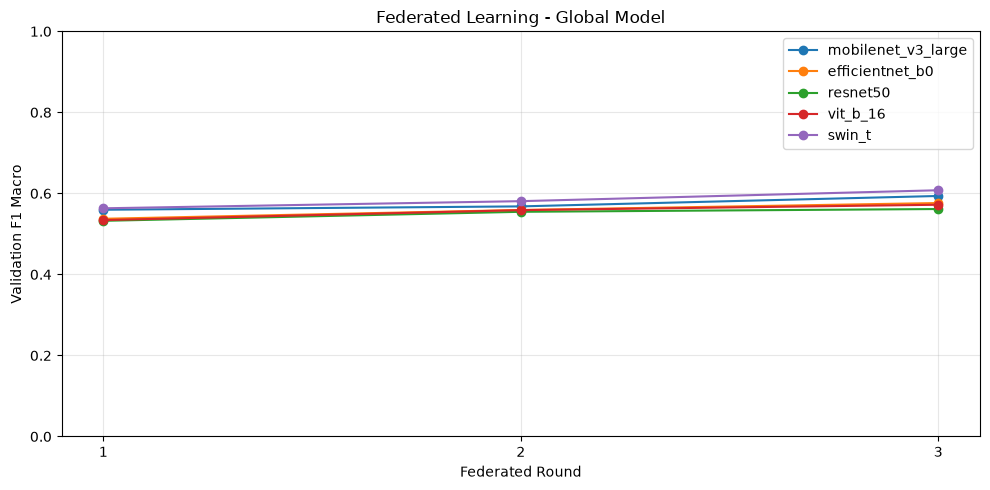

In [36]:
all_round_histories = []

for fold in fed_config["validation_folds"]:

    for model_name in ARCHITECTURES:

        history = pd.read_csv(

            FED_REPORTS_DIR

            / f"validation_fold_{fold}"

            / model_name

            / "round_history.csv"

        )

        history["fold"] = fold

        all_round_histories.append(history)

df_round_history = pd.concat(

    all_round_histories,

    ignore_index=True

)

df_round_history.to_csv(

    FED_REPORTS_DIR

    / "federated_validation_round_history.csv",

    index=False,

    encoding="utf-8-sig"

)

plt.figure(figsize=(10, 5))

for model_name in ARCHITECTURES:

    history = df_round_history[

        df_round_history["architecture"]

        == model_name

    ]

    curve = history.groupby(
        "round"
    )["val_f1_macro"].mean()

    plt.plot(

        curve.index,

        curve.values,

        marker="o",

        label=model_name

    )

plt.xlabel("Federated Round")
plt.ylabel("Validation F1 Macro")
plt.title("Federated Learning - Global Model")
plt.xticks(range(1, fed_config["rounds"] + 1))
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(

    FED_REPORTS_DIR

    / "federated_validation_f1.png",

    dpi=150

)

plt.show()

In [37]:
centralized_validation = []

CV_REPORTS_DIR = (

    REPORTS_DIR

    / "cross_validation"

    / "cv_cached_v1"

)

for fold in fed_config["validation_folds"]:

    for model_name in ARCHITECTURES:

        history = pd.read_csv(

            CV_REPORTS_DIR

            / model_name

            / f"fold_{fold}"

            / "history.csv"

        )

        last_epoch = history.iloc[-1]

        centralized_validation.append({

            "architecture": model_name,

            "validation_fold": fold,

            "centralized_epochs":
                int(last_epoch["epoch"]),

            "centralized_f1_macro":
                last_epoch["val_f1_macro"],

            "centralized_accuracy":
                last_epoch["val_accuracy"]

        })

df_centralized_validation = pd.DataFrame(
    centralized_validation
)

df_validation_comparison = (

    df_centralized_validation.merge(

        df_fed_validation[[

            "architecture",

            "validation_fold",

            "f1_macro",

            "accuracy",

            "rounds_completed"

        ]],

        on=[
            "architecture",
            "validation_fold"
        ],

        validate="one_to_one"

    ).rename(columns={

        "f1_macro": "federated_f1_macro",

        "accuracy": "federated_accuracy"

    })

)

df_validation_comparison["f1_difference_pp"] = (

    df_validation_comparison[
        "federated_f1_macro"
    ]

    - df_validation_comparison[
        "centralized_f1_macro"
    ]

) * 100

display(

    df_validation_comparison.round(4)

)

df_validation_comparison.to_csv(

    FED_REPORTS_DIR

    / "centralized_vs_federated_validation.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,validation_fold,centralized_epochs,centralized_f1_macro,centralized_accuracy,federated_f1_macro,federated_accuracy,rounds_completed,f1_difference_pp
0,mobilenet_v3_large,1,3,0.5526,0.6655,0.5863,0.7199,3,3.3745
1,efficientnet_b0,1,3,0.5868,0.7188,0.5426,0.6602,3,-4.4243
2,resnet50,1,3,0.5737,0.6987,0.5502,0.6756,3,-2.3515
3,vit_b_16,1,3,0.5780,0.6962,0.5443,0.6721,3,-3.3635
4,swin_t,1,3,0.6291,0.7496,0.5893,0.7069,3,-3.9783
5,mobilenet_v3_large,2,3,0.5864,0.7098,0.5975,0.7272,3,1.1121
6,efficientnet_b0,2,3,0.5876,0.6998,0.5973,0.7225,3,0.9723
7,resnet50,2,3,0.5755,0.6950,0.5596,0.6848,3,-1.5923
8,vit_b_16,2,3,0.5783,0.6981,0.5828,0.7192,3,0.4430
9,swin_t,2,3,0.6023,0.7042,0.6130,0.7377,3,1.0683


In [38]:
client_sizes = (

    df_fed_dev

    .groupby("client_id")

    .size()

    .to_dict()

)

steps_per_round = sum(

    math.ceil(

        size / fed_config["batch_size"]

    )

    for size in client_sizes.values()

) * fed_config["local_epochs"]

steps_per_model = (

    steps_per_round

    * fed_config["rounds"]

)

expected_total_steps = (

    steps_per_model

    * len(ARCHITECTURES)

)

expected_local_epochs = (

    fed_config["rounds"]

    * fed_config["local_epochs"]

    * fed_config["num_clients"]

    * len(ARCHITECTURES)

)

print("Client sizes:", client_sizes)

print("Steps per round:", steps_per_round)

print("Steps per model:", steps_per_model)

print("Total optimizer steps:", expected_total_steps)

print("Total local epochs:", expected_local_epochs)

Client sizes: {1: 9093, 2: 9094}
Steps per round: 570
Steps per model: 1710
Total optimizer steps: 8550
Total local epochs: 30


In [39]:
federated_final_results = []

federated_final_errors = []

final_start = time.perf_counter()

for model_name in ARCHITECTURES:

    print("\n" + "=" * 65)

    print(
        "FEDERATED FINAL TRAINING:",
        model_name
    )

    print("=" * 65)

    try:

        result = execute_federated_model(

            model_name=model_name,

            validation_fold=None

        )

        federated_final_results.append(result)

        pd.DataFrame(

            federated_final_results

        ).to_csv(

            FED_REPORTS_DIR

            / "federated_final_results.csv",

            index=False,

            encoding="utf-8-sig"

        )

    except KeyboardInterrupt:

        print("Entrenamiento interrumpido.")

        break

    except Exception as error:

        federated_final_errors.append({

            "architecture": model_name,

            "error": str(error)

        })

        print("Error:", error)

        break

    finally:

        release_memory()

        save_json(

            federated_final_errors,

            FED_EXPERIMENTS_DIR

            / "federated_final_errors.json"

        )

print(

    "Tiempo de ejecución:",

    round(

        (time.perf_counter() - final_start)

        / 60,

        2

    ),

    "minutos"

)

display(

    pd.DataFrame(federated_final_results)

)


FEDERATED FINAL TRAINING: mobilenet_v3_large
mobilenet_v3_large | final | Round 1 | Client 1 | Samples 9093 | F1 local 0.5009
mobilenet_v3_large | final | Round 1 | Client 2 | Samples 9094 | F1 local 0.5108
mobilenet_v3_large | final | Round 2 | Client 1 | Samples 9093 | F1 local 0.5716
mobilenet_v3_large | final | Round 2 | Client 2 | Samples 9094 | F1 local 0.5740
mobilenet_v3_large | final | Round 3 | Client 1 | Samples 9093 | F1 local 0.5961
mobilenet_v3_large | final | Round 3 | Client 2 | Samples 9094 | F1 local 0.5868

FEDERATED FINAL TRAINING: efficientnet_b0
efficientnet_b0 | final | Round 1 | Client 1 | Samples 9093 | F1 local 0.4795
efficientnet_b0 | final | Round 1 | Client 2 | Samples 9094 | F1 local 0.4804
efficientnet_b0 | final | Round 2 | Client 1 | Samples 9093 | F1 local 0.5556
efficientnet_b0 | final | Round 2 | Client 2 | Samples 9094 | F1 local 0.5596
efficientnet_b0 | final | Round 3 | Client 1 | Samples 9093 | F1 local 0.5749
efficientnet_b0 | final | Round 3 |

,architecture,stage,validation_fold,rounds_completed,local_epochs_completed,training_images,validation_images,optimizer_steps,classifier_path,model_path,total_seconds,total_minutes,test_used,artifact_hashes,status
0,mobilenet_v3_large,final,None,3,6,18187,0,1710,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,9.201532,0.153359,False,{'global_classifier.pth': 'df3427fb87e4bbd6008...,success
1,efficientnet_b0,final,None,3,6,18187,0,1710,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,7.293248,0.121554,False,{'global_classifier.pth': '66f738d2e6fd1425612...,success
2,resnet50,final,None,3,6,18187,0,1710,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,8.874642,0.147911,False,{'global_classifier.pth': '3bdaf74375749466b33...,success
3,vit_b_16,final,None,3,6,18187,0,1710,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,9.799537,0.163326,False,{'global_classifier.pth': '9928e69408859dad7d1...,success
4,swin_t,final,None,3,6,18187,0,1710,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,C:\Users\Joseph (YO)\JGM\U\Semestre_10\Intelig...,8.308778,0.138480,False,{'global_classifier.pth': '2e4c3cd3f97f25fe961...,success


In [40]:
df_fed_final = pd.read_csv(

    FED_REPORTS_DIR

    / "federated_final_results.csv"

)

assert len(df_fed_final) == 5

assert df_fed_final["architecture"].is_unique

assert set(df_fed_final["architecture"]) == (
    set(ARCHITECTURES)
)

assert (

    df_fed_final["status"] == "success"

).all()

assert (

    df_fed_final["rounds_completed"]

    == fed_config["rounds"]

).all()

assert (

    df_fed_final["training_images"]

    == len(df_development)

).all()

assert (

    df_fed_final["validation_images"] == 0

).all()

assert (

    df_fed_final["optimizer_steps"]

    == steps_per_model

).all()

assert (

    df_fed_final["optimizer_steps"].sum()

    == expected_total_steps

)

assert (

    df_fed_final["local_epochs_completed"].sum()

    == expected_local_epochs

)

assert not df_fed_final["test_used"].any()

display(

    df_fed_final[[

        "architecture",

        "rounds_completed",

        "local_epochs_completed",

        "training_images",

        "optimizer_steps",

        "total_minutes"

    ]].round(4)

)

,architecture,rounds_completed,local_epochs_completed,training_images,optimizer_steps,total_minutes
0,mobilenet_v3_large,3,6,18187,1710,0.1534
1,efficientnet_b0,3,6,18187,1710,0.1216
2,resnet50,3,6,18187,1710,0.1479
3,vit_b_16,3,6,18187,1710,0.1633
4,swin_t,3,6,18187,1710,0.1385


In [41]:
final_round_histories = []

final_local_histories = []

for model_name in ARCHITECTURES:

    report_dir = (

        FED_REPORTS_DIR

        / "final"

        / model_name

    )

    rounds = pd.read_csv(

        report_dir / "round_history.csv"

    )

    local = pd.read_csv(

        report_dir / "local_history.csv"

    )

    assert len(rounds) == (
        fed_config["rounds"]
    )

    assert np.allclose(

        rounds["client_1_weight"]

        + rounds["client_2_weight"],

        1.0

    )

    assert (

        rounds["training_samples"]

        == len(df_development)

    ).all()

    assert (

        rounds["participating_clients"] == 2

    ).all()

    assert (

        rounds["global_update_norm"] > 0

    ).all()

    expected_steps = local[
        "client_samples"
    ].apply(

        lambda n: math.ceil(

            n / fed_config["batch_size"]

        )

    )

    assert np.array_equal(

        local["optimizer_steps"].to_numpy(),

        expected_steps.to_numpy()

    )

    final_round_histories.append(rounds)

    final_local_histories.append(local)

df_final_rounds = pd.concat(

    final_round_histories,

    ignore_index=True

)

df_final_local = pd.concat(

    final_local_histories,

    ignore_index=True

)

df_final_rounds.to_csv(

    FED_REPORTS_DIR

    / "federated_final_round_history.csv",

    index=False,

    encoding="utf-8-sig"

)

df_final_local.to_csv(

    FED_REPORTS_DIR

    / "federated_final_local_history.csv",

    index=False,

    encoding="utf-8-sig"

)

display(df_final_rounds.round(4))

,architecture,stage,round,participating_clients,training_samples,global_update_norm,client_1_samples,client_1_weight,client_1_update_norm,client_2_samples,client_2_weight,client_2_update_norm,round_seconds
0,mobilenet_v3_large,final,1,2,18187,12.3836,9093,0.5,14.2747,9094,0.5,14.1453,2.9243
1,mobilenet_v3_large,final,2,2,18187,8.0381,9093,0.5,10.7572,9094,0.5,10.5707,2.7907
2,mobilenet_v3_large,final,3,2,18187,7.1149,9093,0.5,10.1279,9094,0.5,9.8523,2.6410
3,efficientnet_b0,final,1,2,18187,1.8807,9093,0.5,1.9949,9094,0.5,2.0049,1.9173
4,efficientnet_b0,final,2,2,18187,1.0284,9093,0.5,1.2297,9094,0.5,1.2760,2.1260
5,efficientnet_b0,final,3,2,18187,0.8530,9093,0.5,1.1300,9094,0.5,1.1174,2.2888
6,resnet50,final,1,2,18187,2.6429,9093,0.5,2.8197,9094,0.5,2.8721,2.7285
7,resnet50,final,2,2,18187,1.6734,9093,0.5,1.9986,9094,0.5,1.9959,2.2568
8,resnet50,final,3,2,18187,1.4355,9093,0.5,1.7881,9094,0.5,1.8117,2.1475
9,vit_b_16,final,1,2,18187,1.4048,9093,0.5,1.4577,9094,0.5,1.4900,1.8069


In [42]:
_, eval_transform = build_transforms(

    CONFIGS_DIR

    / "preprocessing_config.json"

)

sample_indices = np.linspace(

    0,

    len(df_development) - 1,

    num=8,

    dtype=int

)

sample_dataset = CassavaDataset(

    dataframe=df_development.iloc[
        sample_indices
    ].reset_index(drop=True),

    dataset_dir=DATASET_DIR,

    class_mapping=CLASS_MAPPING,

    transform=eval_transform

)

sample_images = torch.stack([

    sample_dataset[i][0]

    for i in range(len(sample_dataset))

]).to(DEVICE)

model_verification = []

for model_name in ARCHITECTURES:

    model_dir = (

        FED_MODELS_DIR

        / "final"

        / model_name

    )

    cache = torch.load(

        CACHE_DIR / f"{model_name}.pth",

        map_location="cpu",

        weights_only=True

    )

    model, metadata = load_final_model(

        model_dir / "federated_model.pth",

        DEVICE

    )

    classifier_checkpoint = torch.load(

        model_dir / "global_classifier.pth",

        map_location="cpu",

        weights_only=True

    )

    classifier = create_classifier(

        model_name=model_name,

        num_classes=NUM_CLASSES,

        dropout=metadata["dropout"]

    ).to(DEVICE)

    classifier.load_state_dict(

        classifier_checkpoint[
            "classifier_state_dict"
        ],

        strict=True

    )

    classifier.eval()

    attribute = CLASSIFIER_ATTRIBUTES[
        model_name
    ]

    model_classifier = getattr(
        model,
        attribute
    )

    assert all(

        torch.equal(

            model_classifier.state_dict()[key]
            .cpu(),

            classifier.state_dict()[key]
            .cpu()

        )

        for key in classifier.state_dict()

    )

    with torch.inference_mode():

        cached_features = cache["features"][
            sample_indices
        ].to(DEVICE)

        cached_probs = torch.softmax(

            classifier(cached_features),

            dim=1

        )

        setattr(

            model,

            attribute,

            torch.nn.Identity()

        )

        try:

            with torch.autocast(

                device_type=DEVICE.type,

                dtype=torch.float16,

                enabled=cache["metadata"][
                    "mixed_precision"
                ]

            ):

                direct_features = model(
                    sample_images
                ).float()

        finally:

            setattr(

                model,

                attribute,

                model_classifier

            )

        direct_probs = torch.softmax(

            model_classifier(direct_features),

            dim=1

        )

        assert torch.isfinite(
            direct_probs
        ).all()

        assert direct_probs.shape == (
            len(sample_indices),
            NUM_CLASSES
        )

        probabilities_close = torch.allclose(

            cached_probs,

            direct_probs,

            atol=0.01,

            rtol=0.01

        )

        agreement = (

            cached_probs.argmax(dim=1)

            == direct_probs.argmax(dim=1)

        ).float().mean().item()

        max_difference = (

            cached_probs - direct_probs

        ).abs().max().item()

    model_verification.append({

        "architecture": model_name,

        "samples_verified": len(sample_indices),

        "prediction_agreement": agreement,

        "max_probability_difference":
            max_difference,

        "probabilities_close":
            probabilities_close,

        "checkpoint_load_success": True

    })

    del model
    del classifier
    del model_classifier
    del cache

    release_memory()

df_model_verification = pd.DataFrame(
    model_verification
)

display(
    df_model_verification.round(6)
)

df_model_verification.to_csv(

    FED_REPORTS_DIR

    / "federated_model_verification.csv",

    index=False,

    encoding="utf-8-sig"

)

assert (

    df_model_verification["probabilities_close"]

).all()

del sample_images

release_memory()

,architecture,samples_verified,prediction_agreement,max_probability_difference,probabilities_close,checkpoint_load_success
0,mobilenet_v3_large,8,1.0,0.001263,True,True
1,efficientnet_b0,8,1.0,0.000484,True,True
2,resnet50,8,1.0,0.000683,True,True
3,vit_b_16,8,1.0,0.000324,True,True
4,swin_t,8,1.0,0.000404,True,True


In [43]:
df_centralized_final = pd.read_csv(

    FINAL_REPORTS_DIR

    / "final_training_results.csv"

)

df_time_comparison = (

    df_centralized_final[[

        "architecture",

        "total_minutes",

        "optimizer_steps"

    ]].rename(columns={

        "total_minutes":
            "centralized_minutes",

        "optimizer_steps":
            "centralized_steps"

    }).merge(

        df_fed_final[[

            "architecture",

            "total_minutes",

            "optimizer_steps"

        ]].rename(columns={

            "total_minutes":
                "federated_minutes",

            "optimizer_steps":
                "federated_steps"

        }),

        on="architecture",

        validate="one_to_one"

    )

)

df_time_comparison["time_ratio"] = (

    df_time_comparison["federated_minutes"]

    / df_time_comparison["centralized_minutes"]

)

display(

    df_time_comparison.round(4)

)

df_time_comparison.to_csv(

    FED_REPORTS_DIR

    / "centralized_vs_federated_time.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,centralized_minutes,centralized_steps,federated_minutes,federated_steps,time_ratio
0,mobilenet_v3_large,0.1131,1707,0.1534,1710,1.3563
1,efficientnet_b0,0.0868,1707,0.1216,1710,1.4005
2,resnet50,0.1263,1707,0.1479,1710,1.1712
3,vit_b_16,0.1300,1707,0.1633,1710,1.2563
4,swin_t,0.1175,1707,0.1385,1710,1.1786


In [44]:
communication_results = []

for model_name in ARCHITECTURES:

    checkpoint = torch.load(

        FED_MODELS_DIR

        / "final"

        / model_name

        / "global_classifier.pth",

        map_location="cpu",

        weights_only=True

    )

    state = checkpoint[
        "classifier_state_dict"
    ]

    parameter_bytes = sum(

        tensor.numel()
        * tensor.element_size()

        for tensor in state.values()

    )

    total_bytes = (

        parameter_bytes

        * fed_config["num_clients"]

        * fed_config["rounds"]

        * 2

    )

    communication_results.append({

        "architecture": model_name,

        "classifier_bytes": parameter_bytes,

        "classifier_mib": (
            parameter_bytes / 1024**2
        ),

        "estimated_communication_mib": (
            total_bytes / 1024**2
        )

    })

    del checkpoint

df_communication = pd.DataFrame(
    communication_results
)

display(
    df_communication.round(4)
)

df_communication.to_csv(

    FED_REPORTS_DIR

    / "estimated_communication.csv",

    index=False,

    encoding="utf-8-sig"

)

,architecture,classifier_bytes,classifier_mib,estimated_communication_mib
0,mobilenet_v3_large,4945940,4.7168,56.6018
1,efficientnet_b0,25620,0.0244,0.2932
2,resnet50,40980,0.0391,0.4690
3,vit_b_16,15380,0.0147,0.1760
4,swin_t,15380,0.0147,0.1760


In [45]:
federated_model_registry = {

    "run_id": RUN_ID,

    "approach": "federated",

    "algorithm": "FedAvg",

    "simulation": True,

    "training_mode":
        "cached_federated_feature_extraction",

    "num_servers": 1,

    "num_clients": 2,

    "rounds": fed_config["rounds"],

    "local_epochs": fed_config["local_epochs"],

    "num_models": len(ARCHITECTURES),

    "num_classes": NUM_CLASSES,

    "class_mapping": CLASS_MAPPING,

    "image_size": [224, 224],

    "preprocessing_config":
        "configs/preprocessing_config.json",

    "test_evaluation_pending": True,

    "models": {}

}

for model_name in ARCHITECTURES:

    model_dir = (

        FED_MODELS_DIR

        / "final"

        / model_name

    )

    model_path = (
        model_dir / "federated_model.pth"
    )

    classifier_path = (
        model_dir / "global_classifier.pth"
    )

    assert model_path.exists()

    assert classifier_path.exists()

    federated_model_registry["models"][
        model_name
    ] = {

        "model_path": str(

            model_path.relative_to(
                PROJECT_DIR
            )

        ),

        "classifier_path": str(

            classifier_path.relative_to(
                PROJECT_DIR
            )

        ),

        "feature_dim": FEATURE_DIMS[
            model_name
        ],

        "dropout": fed_config[
            "hyperparameters"
        ][model_name]["dropout"],

        "rounds": fed_config["rounds"],

        "local_epochs": fed_config[
            "local_epochs"
        ]

    }

save_json(

    federated_model_registry,

    CONFIGS_DIR

    / "federated_model_registry.json"

)

display(federated_model_registry)

{'run_id': 'federated_cached_v1',
 'approach': 'federated',
 'algorithm': 'FedAvg',
 'simulation': True,
 'training_mode': 'cached_federated_feature_extraction',
 'num_servers': 1,
 'num_clients': 2,
 'rounds': 3,
 'local_epochs': 1,
 'num_models': 5,
 'num_classes': 5,
 'class_mapping': {'bacterial_blight': 0,
  'brown_streak_disease': 1,
  'green_mottle': 2,
  'healthy': 3,
  'mosaic_disease': 4},
 'image_size': [224, 224],
 'preprocessing_config': 'configs/preprocessing_config.json',
 'test_evaluation_pending': True,
 'models': {'mobilenet_v3_large': {'model_path': 'models\\federated\\federated_cached_v1\\final\\mobilenet_v3_large\\federated_model.pth',
   'classifier_path': 'models\\federated\\federated_cached_v1\\final\\mobilenet_v3_large\\global_classifier.pth',
   'feature_dim': 960,
   'dropout': 0.062397808134481064,
   'rounds': 3,
   'local_epochs': 1},
  'efficientnet_b0': {'model_path': 'models\\federated\\federated_cached_v1\\final\\efficientnet_b0\\federated_model.pth',


In [46]:
ensemble_config = {

    "experiment_name":
        "heterogeneous_ensemble",

    "run_id": "ensemble_cached_v1",

    "method": "soft_voting",

    "aggregation": "arithmetic_mean",

    "num_models_per_ensemble": 5,

    "architectures": ARCHITECTURES,

    "num_classes": NUM_CLASSES,

    "class_mapping": CLASS_MAPPING,

    "weights": {

        model_name: 1.0 / len(ARCHITECTURES)

        for model_name in ARCHITECTURES

    },

    "centralized_registry":
        "configs/centralized_model_registry.json",

    "federated_registry":
        "configs/federated_model_registry.json",

    "ensembles": [
        "centralized",
        "federated"
    ],

    "evaluation_split": "test",

    "feature_caching": True,

    "test_feature_cache_dir":
        "dataset/cache/test_features_v1",

    "optimize_ensemble_weights": False,

    "test_used_for_model_selection": False

}

save_json(

    ensemble_config,

    CONFIGS_DIR / "ensemble_config.json"

)

display(ensemble_config)

{'experiment_name': 'heterogeneous_ensemble',
 'run_id': 'ensemble_cached_v1',
 'method': 'soft_voting',
 'aggregation': 'arithmetic_mean',
 'num_models_per_ensemble': 5,
 'architectures': ['mobilenet_v3_large',
  'efficientnet_b0',
  'resnet50',
  'vit_b_16',
  'swin_t'],
 'num_classes': 5,
 'class_mapping': {'bacterial_blight': 0,
  'brown_streak_disease': 1,
  'green_mottle': 2,
  'healthy': 3,
  'mosaic_disease': 4},
 'weights': {'mobilenet_v3_large': 0.2,
  'efficientnet_b0': 0.2,
  'resnet50': 0.2,
  'vit_b_16': 0.2,
  'swin_t': 0.2},
 'centralized_registry': 'configs/centralized_model_registry.json',
 'federated_registry': 'configs/federated_model_registry.json',
 'ensembles': ['centralized', 'federated'],
 'evaluation_split': 'test',
 'feature_caching': True,
 'test_feature_cache_dir': 'dataset/cache/test_features_v1',
 'optimize_ensemble_weights': False,
 'test_used_for_model_selection': False}

In [47]:
assert len(df_fed_validation) == (

    len(ARCHITECTURES)

    * len(fed_config["validation_folds"])

)

assert len(df_fed_final) == 5

assert len(df_final_rounds) == (

    len(ARCHITECTURES)

    * fed_config["rounds"]

)

assert len(df_final_local) == (
    expected_local_epochs
)

assert len(df_model_verification) == 5

assert (

    df_model_verification[
        "checkpoint_load_success"
    ]

).all()

assert (

    df_model_verification[
        "probabilities_close"
    ]

).all()

assert len(

    federated_model_registry["models"]

) == 5

assert not df_fed_final["test_used"].any()

assert not df_fed_validation["test_used"].any()

assert fed_config["test_reserved"]

print(
    "Validación y entrenamiento federado "
    "verificados correctamente."
)

Validación y entrenamiento federado verificados correctamente.


In [48]:
federated_summary = {

    "phase": "phase_3",

    "experiment":
        "validation_and_federated_training",

    "run_id": RUN_ID,

    "status": "completed",

    "algorithm": "FedAvg",

    "simulation": True,

    "num_servers": 1,

    "num_clients": 2,

    "architectures": 5,

    "cnn_architectures": 3,

    "transformer_architectures": 2,

    "validation_folds":
        fed_config["validation_folds"],

    "validation_strategy":
        fed_config["validation_strategy"],

    "federated_cross_validation":
        fed_config["validation_cross_validation"],

    "validation_experiments":
        len(df_fed_validation),

    "final_experiments":
        len(df_fed_final),

    "rounds_per_model":
        fed_config["rounds"],

    "local_epochs_per_round":
        fed_config["local_epochs"],

    "final_aggregations":
        len(df_final_rounds),

    "final_local_epochs":
        len(df_final_local),

    "validation_local_epochs": int(

        df_fed_validation[
            "local_epochs_completed"
        ].sum()

    ),

    "training_images":
        len(df_development),

    "test_images_reserved":
        len(df_test),

    "feature_caching": True,

    "partial_finetuning": False,

    "federated_models_saved": 5,

    "classifier_checkpoints_saved": 5,

    "models_verified": int(

        df_model_verification[
            "checkpoint_load_success"
        ].sum()

    ),

    "validation_minutes": float(

        df_fed_validation[
            "total_minutes"
        ].sum()

    ),

    "final_training_minutes": float(

        df_fed_final[
            "total_minutes"
        ].sum()

    ),

    "estimated_communication_mib": float(

        df_communication[
            "estimated_communication_mib"
        ].sum()

    ),

    "communication_measured": False,

    "model_registry_generated": True,

    "ensemble_config_generated": True,

    "test_used": False,

    "test_evaluation_deferred_to":
        "phase_4",

    "timestamp":
        datetime.now().isoformat()

}

federated_summary["total_compute_minutes"] = (

    federated_summary["validation_minutes"]

    + federated_summary["final_training_minutes"]

)

save_json(

    federated_summary,

    FED_EXPERIMENTS_DIR

    / "federated_training_summary.json"

)

display(federated_summary)

print("=" * 65)

print(
    "FASE 3 - VALIDACIÓN Y ENTRENAMIENTO "
    "FEDERADO COMPLETADA"
)

print("=" * 65)

release_memory()

{'phase': 'phase_3',
 'experiment': 'validation_and_federated_training',
 'run_id': 'federated_cached_v1',
 'status': 'completed',
 'algorithm': 'FedAvg',
 'simulation': True,
 'num_servers': 1,
 'num_clients': 2,
 'architectures': 5,
 'cnn_architectures': 3,
 'transformer_architectures': 2,
 'validation_folds': [1, 2, 3],
 'validation_strategy': 'stratified_3_fol',
 'federated_cross_validation': True,
 'validation_experiments': 15,
 'final_experiments': 5,
 'rounds_per_model': 3,
 'local_epochs_per_round': 1,
 'final_aggregations': 15,
 'final_local_epochs': 30,
 'validation_local_epochs': 90,
 'training_images': 18187,
 'test_images_reserved': 3210,
 'feature_caching': True,
 'partial_finetuning': False,
 'federated_models_saved': 5,
 'classifier_checkpoints_saved': 5,
 'models_verified': 5,
 'validation_minutes': 1.51750528333323,
 'final_training_minutes': 0.7246289533333159,
 'estimated_communication_mib': 57.71598815917969,
 'communication_measured': False,
 'model_registry_gener

FASE 3 - VALIDACIÓN Y ENTRENAMIENTO FEDERADO COMPLETADA
